##**5.2 합성곱 신경망 맛보기**

: fashion_mnist 데이터셋을 사용하여 합성곱 신경망을 직접 구현

> fashion_mnist 데이터셋을 토치비전에 내장된 예제 데이터로, 운동화, 셔츠, 샌들 같은 작은 이미지의 모음이며, 기본 MNIST 데이터셋처럼 열 가지로 분류될 수 있는 이미지 7만 개로 구성되어 있음

In [1]:
# 라이브러리 호출

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.autograd import Variable
import torch.nn.functional as F

import torchvision
import torchvision.transforms as transforms # 데이터 전처리를 위해 사용하는 라이브러리
from torch.utils.data import Dataset, DataLoader

- 파이토치는 기본적으로 GPU 사용을 권장



In [2]:
# CPU 혹은 GPU 장치 확인
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

In [3]:
# fashion_mnist 데이터셋 내려받기

train_dataset = torchvision.datasets.FashionMNIST(".. /chap05/data", download=True,
                            transform=transforms.Compose([transforms.ToTensor()]))
test_dataset = torchvision.datasets.FashionMNIST(".. /chap05/data", download=True,
                            train=False, transform=transforms.Compose([transforms.ToTensor()]))

100%|██████████| 26.4M/26.4M [00:01<00:00, 19.1MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 308kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.63MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 3.28MB/s]


- torchvision.datasets는 torch.utils.data.Dataset의 하위 클래스로 다양한 데이터셋을 포함 (CIFAR, COCO, MNIST, ImageNet 등)

In [4]:
# fashion_mnist 데이터를 데이터로더에 전달

train_loader = torch.utils.data.DataLoader(train_dataset,
                                           batch_size=100)
test_loader = torch.utils.data.DataLoader(test_dataset,
                                          batch_size=100)

- torch.utils.data.DataLoader()를 사용하여 원하는 크기의 배치 단위로 데이터를 불러오거나, 순서가 문작위로 섞이도록 할 수 있음

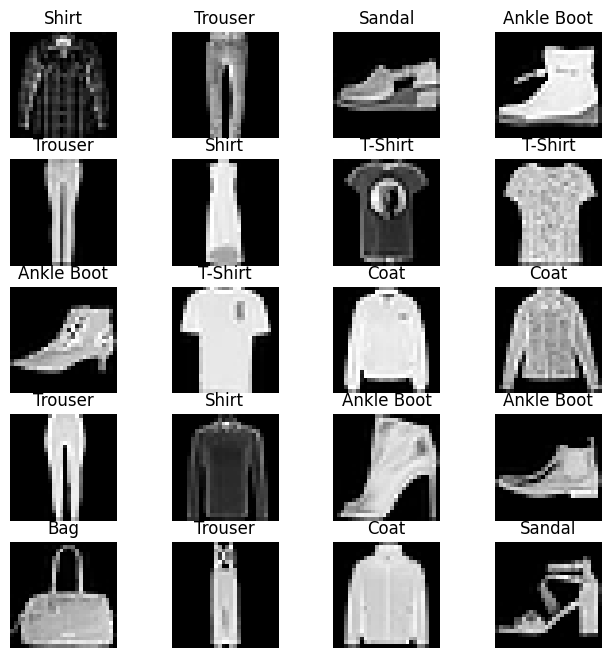

In [5]:
# 분류에 사용될 클래스 정의

labels_map = {0: 'T-Shirt', 1: 'Trouser', 2: 'Pullover', 3: 'Dress', 4:'Coat',
              5: 'Sandal', 6: 'Shirt', 7: 'Sneaker', 8: 'Bag', 9: 'Ankle Boot'}

fig = plt.figure(figsize=(8,8)); # 출력할 이미지의 가로세로 길이로 단위는 inch
columns = 4;
rows = 5;
for i in range(1, columns*rows +1):
    img_xy = np.random.randint(len(train_dataset));
    img = train_dataset[img_xy][0][0,:,:]
    fig.add_subplot(rows, columns, i)
    plt.title(labels_map[train_dataset[img_xy][1]])
    plt.axis('off')
    plt.imshow(img, cmap='gray')
plt.show()

- np.random은 무작위로 데이터를 생성할 때 사용
- np.randon.randint()는 이산형 분포를 갖는 데이터에서 무작위 표본을 추출할 때 사용
- 따라서 random.randint(len(train_dataset)) 의미는 0~train_dataset 길이 값을 갖는 분포에서 랜덤한 숫자 한 개를 생성하라는 의미

In [6]:
# 심층 신경망 모델 생성

class FashionDNN(nn.Module):
    def __init__(self):
        super(FashionDNN, self).__init__()
        self.fc1 = nn.Linear(in_features=784, out_features=256)
        self.drop = nn.Dropout(0.25)
        self.fc2 = nn.Linear(in_features=256, out_features=128)
        self.fc3 = nn.Linear(in_features=128, out_features=10)

    def forward(self, input_data):
        out = input_data.view(-1, 784)
        out = F.relu(self.fc1(out))
        out = self.drop(out)
        out = F.relu(self.fc2(out))
        out = self.fc3(out)
        return out

- class 형태의 모델은 항상 torch.nn.Module을 상속받음
- init()은 객체가 갖는 속성 값을 초기화하는 역할
- nn은 딥러닝 모델 구성에 필요한 모듈이 모여 있는 패키지
- Linear는 단순 선형 회귀 모델을 만들 때 사용
- torch.nn.Dropout(p)는 p만큼의 비율로 텐서의 값이 0이 되고, 0이 되지 않는 값들은 기존 값에 (1/(1-p))만큼 곱해져 커짐
- forward() 함수는 모델이 학습 데이터를 입력받아서 순전파 학습을 진행시키는 함수이며, 객체를 데이터와 함께 호출하면 자동으로 실행
- 파이토치에서 사용하는 view는 넘파이의 reshape과 같은 역할로 텐서의 크기를 변경해주는 역할
- 활성화 함수를 지정할 때는 **F.relu()** or **nn.ReLU()** 함수에서 정의 가능
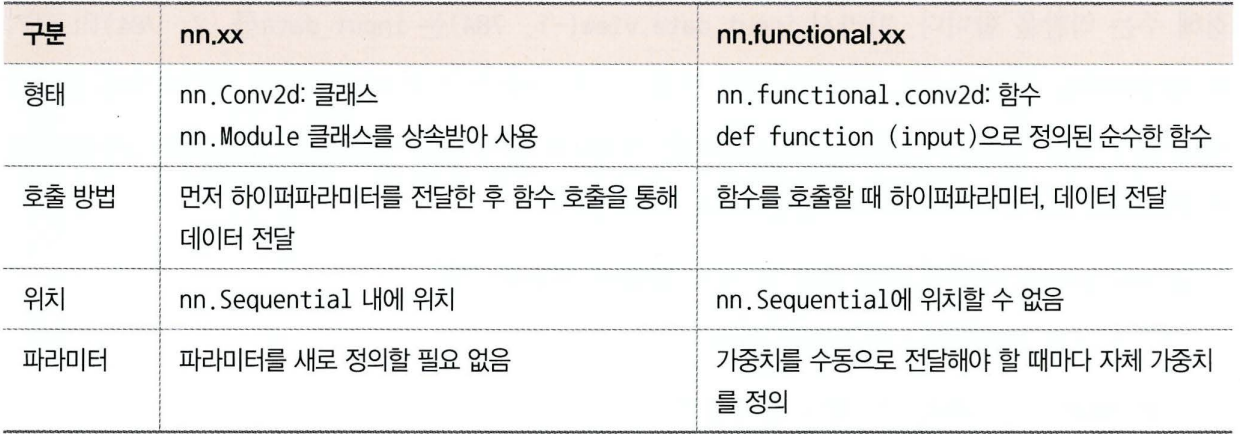

In [7]:
# 심층 신경망에서 필요한 파라미터 정의

learning_rate = 0.001;
model = FashionDNN();
model.to(device)

criterion = nn.CrossEntropyLoss (); # 분류 문제에서 사용하는 손실 함수
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate);
print(model)

FashionDNN(
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (drop): Dropout(p=0.25, inplace=False)
  (fc2): Linear(in_features=256, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=10, bias=True)
)


- 옵티마이저를 위한 경사 하강법은 Adam을 사용하며, 학습률을 의미하는 lr은 0.001을 사용


In [8]:
# 심층 신경망을 이용한 모델 학습

num_epochs = 5
count = 0

loss_list = []
iteration_list = []
accuracy_list = []

predictions_list = []
labels_list = []

for epoch in range(num_epochs):
  for images, labels in train_loader:
      images, labels = images.to(device), labels.to(device)

      train = Variable(images.view(100, 1, 28, 28))
      labels = Variable(labels)

      outputs = model(train) # 학습 데이터를 모델에 적용
      loss = criterion(outputs, labels)
      optimizer.zero_grad()
      loss.backward()
      optimizer.step()
      count += 1

      if not (count % 50): # count를 50으로 나누었을 때 나머지가 0이 아니라면 실행
        total = 0
        correct = 0
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            labels_list.append(labels)
            test = Variable(images.view(100, 1, 28, 28))
            outputs = model(test)
            predictions = torch.max(outputs, 1)[1].to(device)
            predictions_list.append(predictions)
            correct += (predictions == labels).sum()
            total += len(labels)

        accuracy = correct * 100 / total
        loss_list.append(loss. data)
        iteration_list.append(count)
        accuracy_list.append(accuracy)

      if not (count % 500):
         print("Iteration: {}, Loss: {}, Accuracy: {}%" .format(count, loss.data,
                                                             accuracy))

Iteration: 500, Loss: 0.591081440448761, Accuracy: 83.12999725341797%
Iteration: 1000, Loss: 0.4725116789340973, Accuracy: 84.30999755859375%
Iteration: 1500, Loss: 0.3696369528770447, Accuracy: 84.66000366210938%
Iteration: 2000, Loss: 0.38964807987213135, Accuracy: 85.91000366210938%
Iteration: 2500, Loss: 0.25781014561653137, Accuracy: 86.5199966430664%
Iteration: 3000, Loss: 0.31571629643440247, Accuracy: 86.55000305175781%


- 비어 있는 배열이나 행렬을 만든 후, append 메서드를 이용하여 데이터를 하나씩 추가
- for 구문을 사용하여 레코드를 하나씩 가져옴
- 모델이 데이터를 처리하기 위해서는 모델과 데이터가 동일한 장치에 있어야 함
- Autograd는 자동 미분을 수행하는 파이토치의 핵심 패키지로, 자동 미분에 대한 값을 저장하기 위해 테이프를 새용. 순전파 단계에서 테이프는 수행하는 모든 연산을 저장. 그리고 역전파 단계에서 저장된 값들을 꺼내서 사용
- 즉, Autograd는 Variable을 사용해서 역전파를 위한 미분 값을 자동으로 계산. 따라서 자동 미분을 계산하기 위해서는 torch.autograd 패키지 안에 있는 Variable을 이용해야 동작
- 분류 문제에서 클래스가 세 개 이상일 때는 정확도 값이 모든 클래스가 동등하게 고려된 것인지, 특정 클래스의 분류가 높았던 것인지에 대해 알 수 없음에 유의
- 분류 문제에서 클래스가 세 개 이상일 때는 데이터 특성에 따라 정확도를 잘 관측해야 함



In [9]:
# 합성곱 네트워크 생성

class FashionCNN(nn.Module):
    def __init__(self):
        super(FashionCNN, self).__init__()
        self.layer1 = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.layer2 = nn.Sequential(
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.fc1 = nn.Linear(in_features=64*6*6, out_features=600)
        self.drop = nn.Dropout(0.25)
        self.fc2 = nn.Linear(in_features=600, out_features=120)
        self.fc3 = nn.Linear(in_features=120, out_features=10)

    def forward(self, x):
        out = self.layer1(x)
        out = self.layer2(out)
        out = out.view(out.size(0), -1)
        out = self.fc1(out)
        out = self.drop(out)
        out = self.fc2(out)
        out = self.fc3(out)
        return out

- nn.Sequential을 사용하면 init()에서 사용할 네트워크 모델들을 정의해 줄 뿐만 아니라, forward() 함수에서 구현될 순전파를 계층 형태로 좀 더 가독성이 뛰어난 코드로 작성할 수 있음
- 즉, 계층을 차례로 쌓을 수 있도록 Wx+b와 같은 수식과 활성화 함수를 연결해 주는 역할을 함
- 합성곱층은 합성곱 연산을 통해 이미지의 특징을 추출
- 합성곱이란 커널이라는 nxm 크기의 행렬이 높이x너비 크기의 이미지를 처음부터 훑으면서 각 원소 값끼리 곱한 후 모두 더한 값을 출력
- BatchNorm2d는 학습 과정에서 각 배치 단위별로 데이터가 다양한 분포를 가지더라도 평균과 분산을 이용해서 정규화하는 것
- MaxPool2d는 이미지 크기를 축소시키는 용도로 사용
- 풀링 계층은 합성곱층의 출력 데이터를 입력으로 받아서 출력 데이터의 크기를 줄이거나 특정 데이터를 강조하는 용도로 사용됨
- 클래스를 분류하기 위해서는 이미지 형태의 데이터를 배열 형태로 변환하여 작업해야 함. 패딩과 스트라이드 값에 따라 출력 크기가 달라짐
- in_features은 입력 데이터의 크기를 의미
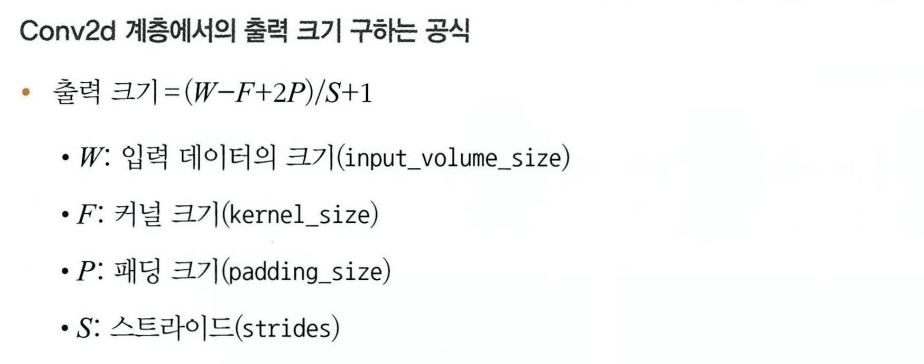

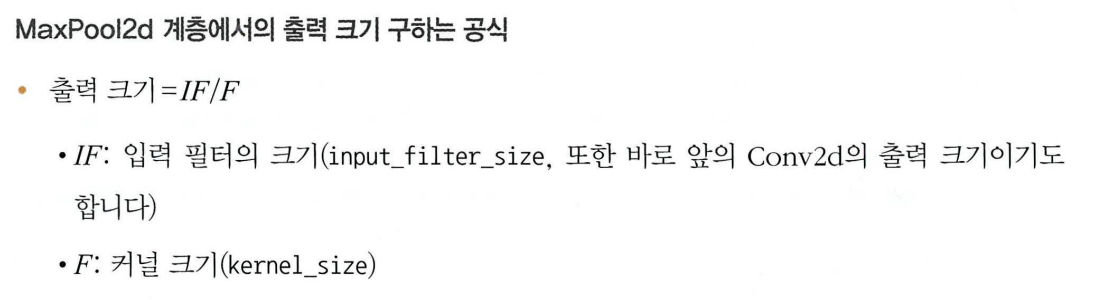

- 합성곱층에서 완전연결층으로 변경되기 때문에 데이터의 형태를 1차원으로 바꾸어 줌
- 이때 out.size(0)은 결국 100을 의미.




In [10]:
# 합성곱 네트워크를 위한 파라미터 정의

learning_rate = 0.001;
model = FashionCNN();
model.to(device)

criterion = nn.CrossEntropyLoss();
optimizer = torch.optim.Adam(model.parameters(), lr = learning_rate);
print(model)

FashionCNN(
  (layer1): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (layer2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc1): Linear(in_features=2304, out_features=600, bias=True)
  (drop): Dropout(p=0.25, inplace=False)
  (fc2): Linear(in_features=600, out_features=120, bias=True)
  (fc3): Linear(in_features=120, out_features=10, bias=True)
)


In [11]:
# 모델 학습 및 성능 평가

num_epochs = 5
count = 0
loss_list = []
iteration_list = []
accuracy_list = []

predictions_list = []
labels_list = []

for epoch in range(num_epochs):
  for images, labels in train_loader:
      images, labels = images.to(device), labels.to(device)

      train = Variable(images.view(100, 1, 28, 28))
      labels = Variable(labels)

      outputs = model(train)
      loss = criterion(outputs, labels)
      optimizer.zero_grad()
      loss.backward()
      optimizer.step()
      count += 1

      if not (count % 50):
        total = 0
        correct = 0
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            labels_list.append(labels)
            test = Variable(images.view(100, 1, 28, 28))
            outputs = model(test)
            predictions = torch.max(outputs, 1)[1].to(device)
            predictions_list.append(predictions)
            correct += (predictions == labels).sum()
            total += len(labels)

        accuracy = correct * 100 / total
        loss_list.append(loss.data)
        iteration_list.append(count)
        accuracy_list.append(accuracy)

      if not (count % 500):
         print("Iteration: {}, Loss: {}, Accuracy: {}%" .format(count, loss.data,
                accuracy))

Iteration: 500, Loss: 0.460153192281723, Accuracy: 88.1500015258789%
Iteration: 1000, Loss: 0.32654520869255066, Accuracy: 88.83000183105469%
Iteration: 1500, Loss: 0.2981015145778656, Accuracy: 88.5999984741211%
Iteration: 2000, Loss: 0.25205397605895996, Accuracy: 89.86000061035156%
Iteration: 2500, Loss: 0.14004497230052948, Accuracy: 89.5%
Iteration: 3000, Loss: 0.17033904790878296, Accuracy: 90.13999938964844%
